# [GSE135318](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE135318)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-01-20
> - Modified: 2025-05-17

# 1. Experimental Design

> DOT1L-mediated Murine Neuronal Differentiation associates with H3K79me2 Accumulation and preserves SOX2-Enhancer Accessibility.
> - Ferrari, F., Arrigoni, L., Franz, H. et al. DOT1L-mediated murine neuronal differentiation associates with H3K79me2 accumulation and preserves SOX2-enhancer accessibility. Nat Commun 11, 5200 (2020). https://doi.org/10.1038/s41467-020-19001-7.
> - Mus musculus embryonic stem cells, C57BL/6, Dot1l-HA-FLAG
> - ChIP-seq
> - mm10

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/chipseq_Mm_mESC_DOT1L_GSE135318/04_output_chipseq"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "(.*)_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> 
    head() |> cat(sep = "\n")

mESC_DMSO_rep1_H3K27ac: mESC_DMSO_rep1_H3K27ac_peaks.narrowPeak
mESC_DMSO_rep1_H3K27me3: mESC_DMSO_rep1_H3K27me3_peaks.narrowPeak
mESC_DMSO_rep1_H3K36me3: mESC_DMSO_rep1_H3K36me3_peaks.narrowPeak
mESC_DMSO_rep1_H3K4me1: mESC_DMSO_rep1_H3K4me1_peaks.narrowPeak
mESC_DMSO_rep1_H3K4me3: mESC_DMSO_rep1_H3K4me3_peaks.narrowPeak
mESC_DMSO_rep1_H3K79me2: mESC_DMSO_rep1_H3K79me2_peaks.narrowPeak


In [6]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

## 2). Import bigwig

In [7]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R")

In [8]:
signals_files <- file.path(data_dir, "07_bigwig") |>
    list.files(pattern = ".bw$", full.names = TRUE) |>
    set_names(~ sub("(.*)\\.bw$", "\\1", basename(.x)))

paste(names(signals_files), basename(signals_files), sep = ": ") |>
    head() |> cat(sep = "\n")

mESC_DMSO_rep1_H3K27ac: mESC_DMSO_rep1_H3K27ac.bw
mESC_DMSO_rep1_H3K27me3: mESC_DMSO_rep1_H3K27me3.bw
mESC_DMSO_rep1_H3K36me3: mESC_DMSO_rep1_H3K36me3.bw
mESC_DMSO_rep1_H3K4me1: mESC_DMSO_rep1_H3K4me1.bw
mESC_DMSO_rep1_H3K4me3: mESC_DMSO_rep1_H3K4me3.bw
mESC_DMSO_rep1_H3K79me2: mESC_DMSO_rep1_H3K79me2.bw


In [9]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

In [10]:
marks <- c(
    "H3K4me3", "H3K4me1", "H3K27ac", "H3K36me3", 
    "H3K79me2", "H3K27me3", "H3K9me3")

coldata <- data.frame(sample = names(signals_files)) |>
    separate(
        sample, into = c("Cell", "Treatment", "Replicate", "Mark"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("DMSO", "EPZ5676")),
        Replicate = factor(Replicate),
        Group = forcats::fct_cross(Treatment, Replicate, sep = "_"),
        Mark = factor(Mark, levels = c(marks, "Input"))) |>
    arrange(Treatment, Replicate, Mark) |>
    column_to_rownames("sample")

head(coldata)

,Cell,Treatment,Replicate,Mark,Group
,<chr>,<fct>,<fct>,<fct>,<fct>
mESC_DMSO_rep1_H3K4me3,mESC,DMSO,rep1,H3K4me3,DMSO_rep1
mESC_DMSO_rep1_H3K4me1,mESC,DMSO,rep1,H3K4me1,DMSO_rep1
mESC_DMSO_rep1_H3K27ac,mESC,DMSO,rep1,H3K27ac,DMSO_rep1
mESC_DMSO_rep1_H3K36me3,mESC,DMSO,rep1,H3K36me3,DMSO_rep1
mESC_DMSO_rep1_H3K79me2,mESC,DMSO,rep1,H3K79me2,DMSO_rep1
mESC_DMSO_rep1_H3K27me3,mESC,DMSO,rep1,H3K27me3,DMSO_rep1


# 3. Evaluate Library Quality

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [11]:
plot_df <- data.frame(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Cell", "Treatment", "Replicate", "Mark"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("DMSO", "EPZ5676")),
        Replicate = factor(Replicate),
        Group = forcats::fct_cross(Treatment, Replicate, sep = "_"),
        Mark = factor(Mark, levels = marks),
        number = lengths(peaks_list)) |>
    arrange(Treatment, Replicate, Mark) |>
    column_to_rownames("sample")

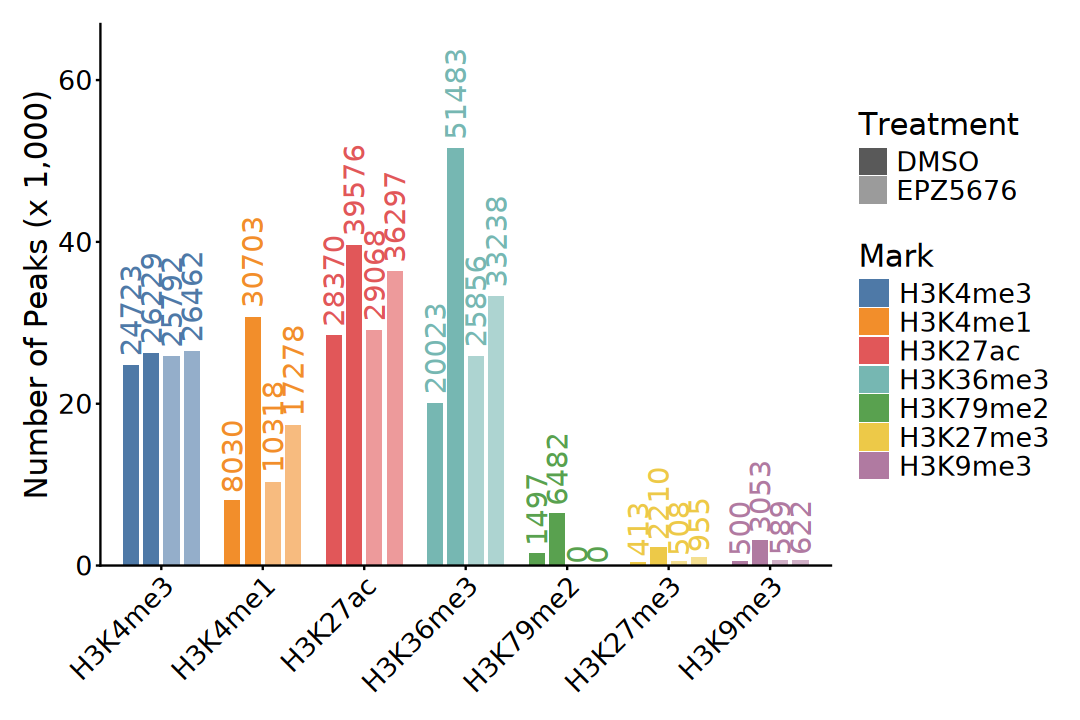

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(Mark, number)) +
    geom_bar(
        aes(fill = Mark, alpha = Treatment, group = Group), 
        position = position_dodge(width = 0.8), 
        stat = "identity", width = 0.6) +
    geom_text(
        aes(color = Mark, group = Group, label = number), 
        position = position_dodge(width = 0.8),
        angle = 90, hjust = -0.1, vjust = 0.5, size = 6) +
    scale_y_continuous(
        labels = function(x) x / 1000, 
        expand = expansion(mult = c(0, 0.3))) + 
    ggthemes::scale_color_tableau(palette = "Tableau 10") +
    ggthemes::scale_fill_tableau(palette = "Tableau 10") +
    scale_alpha_manual(values = c("DMSO" = 1.0, "EPZ5676" = 0.6)) +
    # guides(color = guide_legend(nrow = 3), alpha = guide_legend(nrow = 2)) +
    labs(x = NULL, y = "Number of Peaks (x 1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
        axis.text.y = element_text(size = 16))

In [13]:
peaks_list <- peaks_list[lengths(peaks_list) > 0]

## 3). Fingerprints

> - Diaz, A., Nellore, A. & Song, J.S. CHANCE: comprehensive software for quality control and validation of ChIP-seq data. Genome Biol 13, R98 (2012). https://doi.org/10.1186/gb-2012-13-10-r98

In [14]:
# Cumulative Distribution Function
plot_df <- file.path(data_dir, "01_stats", "fingerprint.tsv") |>
    read.table(
        header = TRUE, sep = "\t", check.names = FALSE, comment.char = "#") |>
    pivot_longer(
        cols = everything(), names_to = "Sample", values_to = "Counts") |>
    separate_wider_delim(
        cols = Sample, names = c("Cell", "Treatment", "Replicate", "Mark"),
        delim = "_", cols_remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("DMSO", "EPZ5676")),
        Replicate = factor(Replicate),
        Group = forcats::fct_cross(Treatment, Replicate, sep = "_"),
        Mark = factor(Mark, levels = c(marks, "Input"))) |>
    arrange(Sample, Counts) |>
    group_by(Sample) |>
    mutate(
        cum_reads = cumsum(Counts),
        fraction_reads = cum_reads / last(cum_reads),
        fraction_bins = row_number() / n()) |>
    ungroup()

head(plot_df)

Cell,Treatment,Replicate,Mark,Sample,Counts,Group,cum_reads,fraction_reads,fraction_bins
<chr>,<fct>,<fct>,<fct>,<chr>,<int>,<fct>,<int>,<dbl>,<dbl>
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,2.165496e-06
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,4.330992e-06
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,6.496488e-06
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,8.661983e-06
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,1.082748e-05
mESC,DMSO,rep1,H3K27ac,mESC_DMSO_rep1_H3K27ac,0,DMSO_rep1,0,0,1.299298e-05


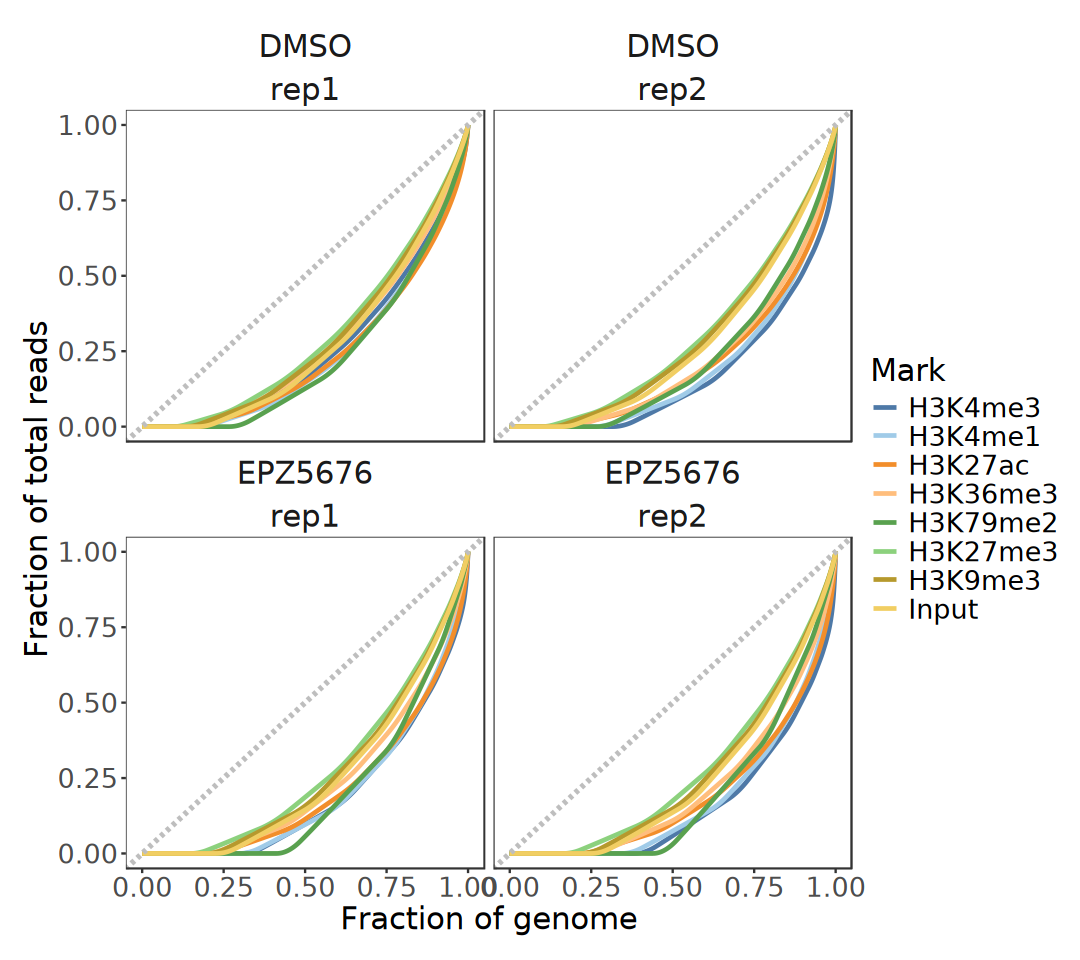

In [15]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = fraction_bins, y = fraction_reads)) +
    geom_line(aes(color = Mark), linewidth = 1) +
    geom_abline(
        slope = 1, intercept = 0, color = "gray", 
        linetype = "dashed", linewidth = 1.2) +
    facet_wrap(Treatment ~ Replicate) +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    labs(x = "Fraction of genome", y = "Fraction of total reads") +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [16]:
bin_means_df <- file.path(data_dir, "09_count", "bins_10kb.counts.tsv") |>
    read.table(header = TRUE, sep = "\t", comment.char = "") |>
    dplyr::rename(chr = X.chr) |>
    mutate(pos = paste0(chr, ":", start, "-", end)) |>
    select(-chr, -start, -end) |>
    column_to_rownames("pos") |>
    # filter(if_any(everything(), ~ var(.x, na.rm = TRUE) > 0))
    slice_max(
        order_by = apply(as.matrix(pick(everything())), 1, var), n = 2000
    )

bin_means_df[1:6, 1:2]

,mESC_DMSO_rep1_H3K27ac,mESC_DMSO_rep1_H3K27me3
,<dbl>,<dbl>
chr17:39843171-39853171,2206,1953
chr8:84652684-84662684,1082,162
chr7:3210000-3220000,1149,150
chr7:3200000-3210000,1117,154
chr19:5840000-5850000,1067,175
chr11:3190000-3200000,1057,1322


In [17]:
cor_mat <- cor(bin_means_df, method = "spearman")

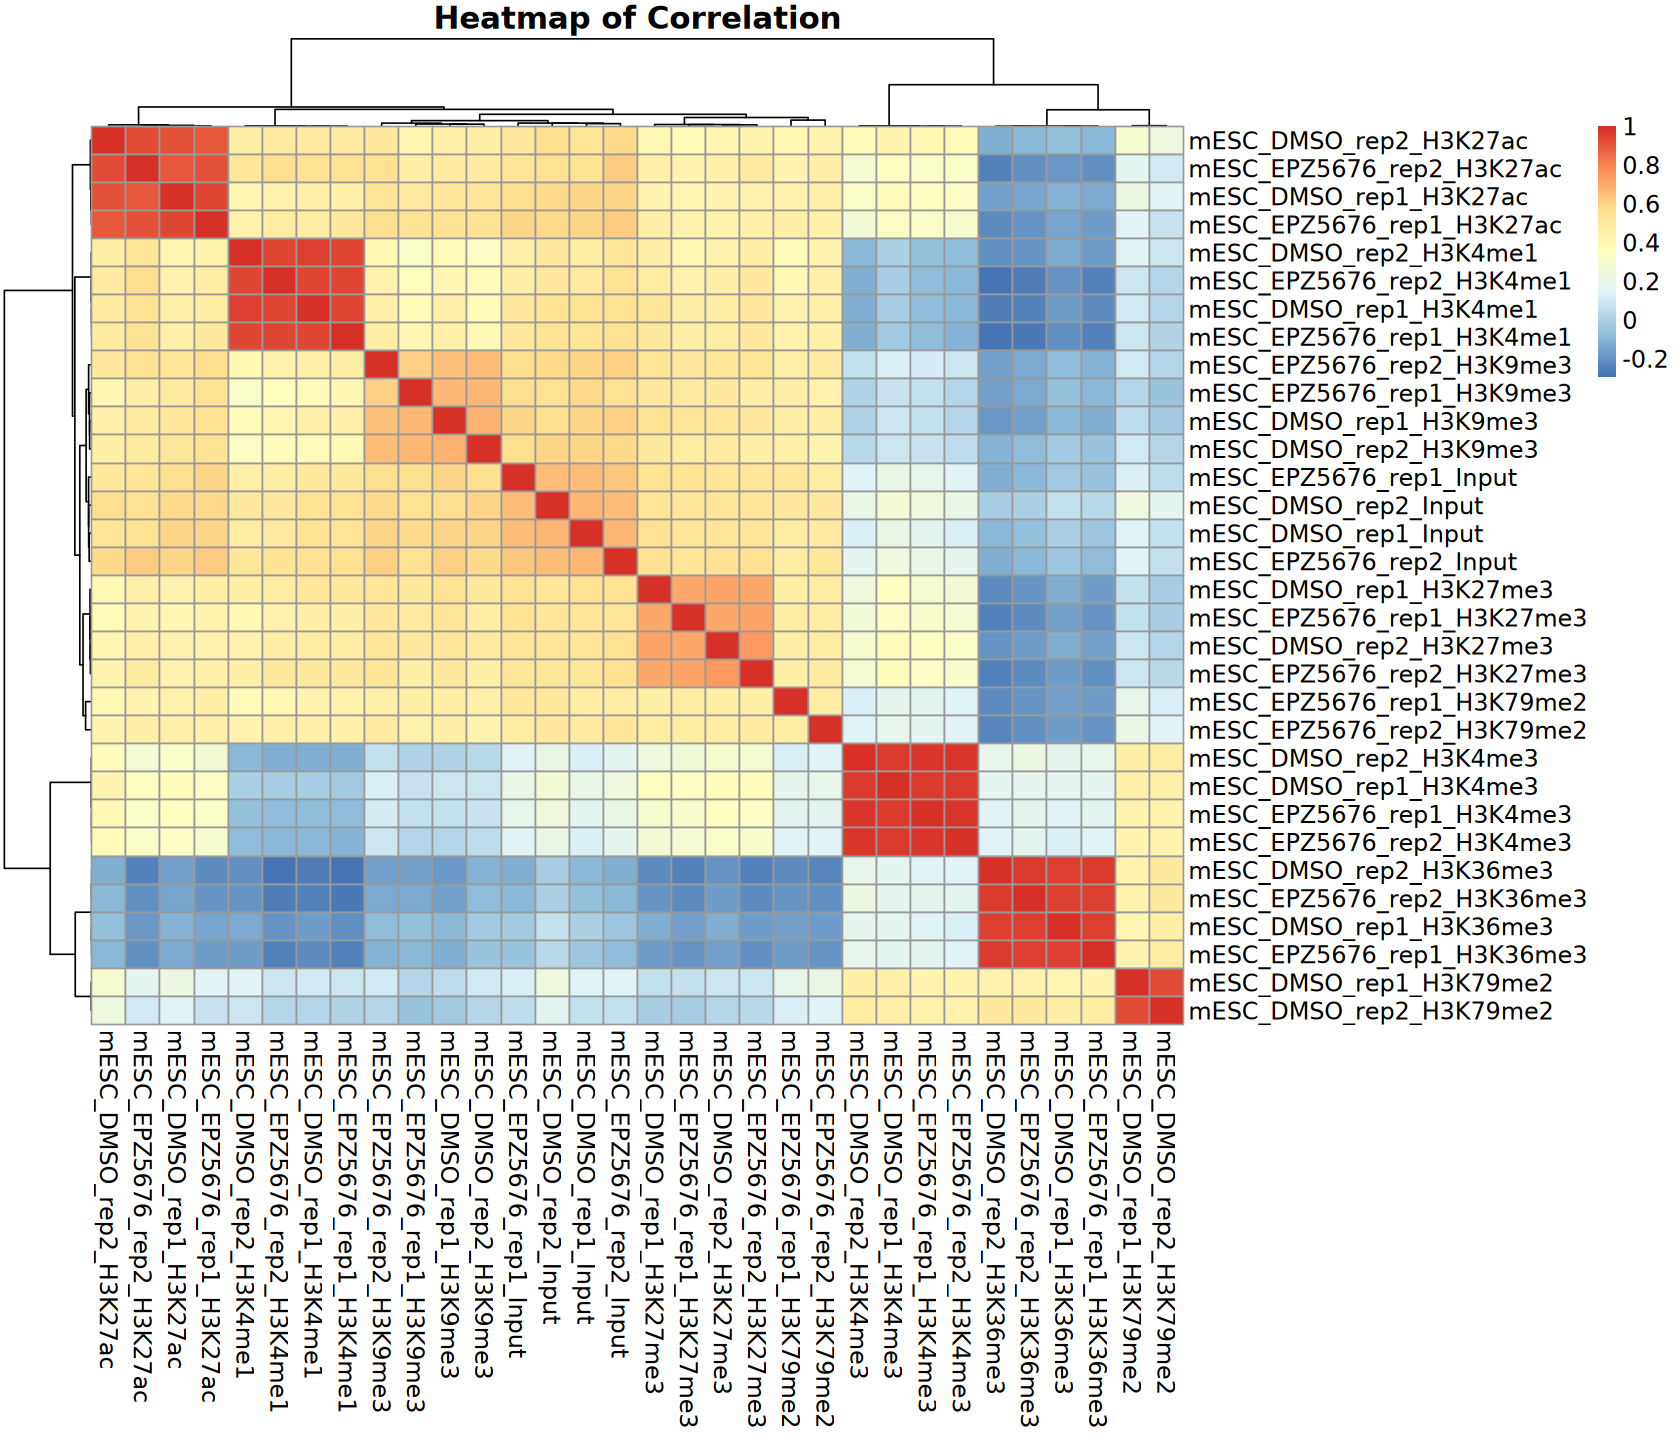

In [18]:
options(repr.plot.width = 14, repr.plot.height = 12)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation", 
    clustering_distance_cols = "correlation", 
    main = "Heatmap of Correlation", fontsize = 14, 
    show_colnames = TRUE, show_rownames = TRUE)

In [19]:
pca_df <- bin_means_df |> t() |>
    prcomp(center = TRUE, scale. = TRUE)

per_var <- round(pca_df$sdev^2 / sum(pca_df$sdev^2) * 100, 2)

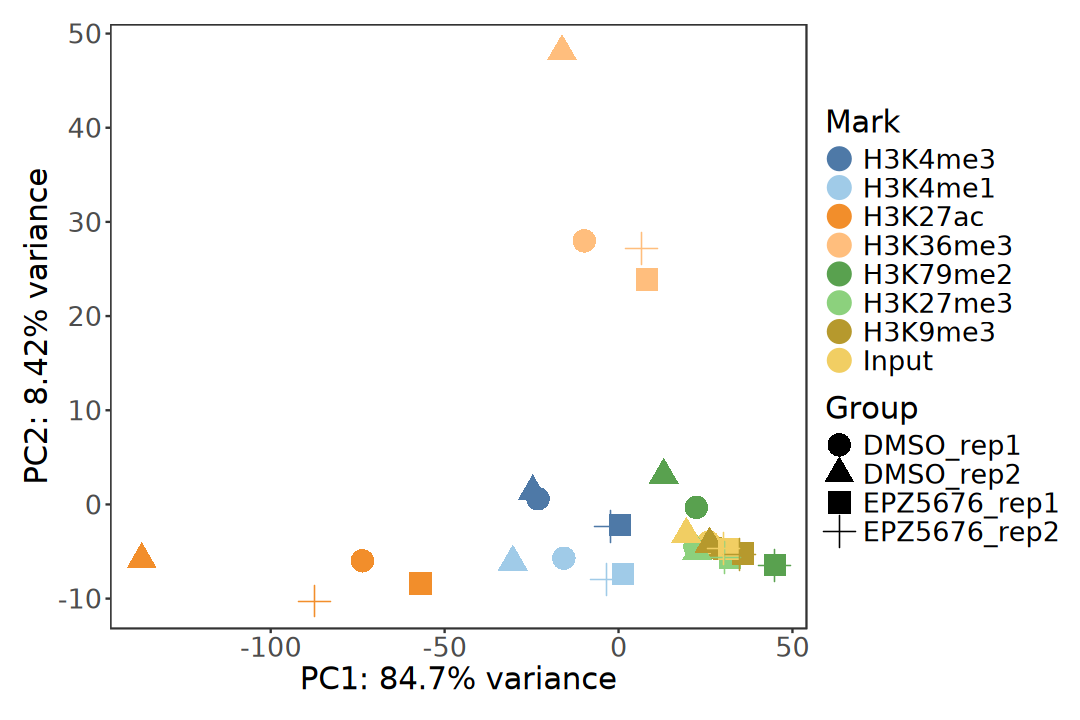

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)

pca_df$x |> as.data.frame() |> 
    rownames_to_column(var = "Sample") |>
    separate(
        Sample, into = c("Cell", "Treatment", "Replicate", "Mark"),
        sep = "_", remove = FALSE) |>
    mutate(
        Treatment = factor(Treatment, levels = c("DMSO", "EPZ5676")),
        Replicate = factor(Replicate),
        Group = forcats::fct_cross(Treatment, Replicate, sep = "_"),
        Mark = factor(Mark, levels = c(marks, "Input"))) |>
ggplot(aes(PC1, PC2)) +
    geom_point(aes(color = Mark, shape = Group), size = 6) +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Metagene Profile

In [21]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [22]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [23]:
# ~ 40 minutes
gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "w0", extend = 2000, w = 50, smooth = FALSE, 
    target_ratio = 0.4, background = NA)

In [24]:
gene_mat_merged_list <- lapply(marks, function(mark) {
    rbind.normalizedMatrix(
        gene_mat_list[[paste0("mESC_DMSO_rep1_", mark)]],
        gene_mat_list[[paste0("mESC_DMSO_rep2_", mark)]],
        gene_mat_list[[paste0("mESC_EPZ5676_rep1_", mark)]],
        gene_mat_list[[paste0("mESC_EPZ5676_rep2_", mark)]]
    )
})

names(gene_mat_merged_list) <- marks

In [25]:
partition <- c(
    "mESC_DMSO_rep1", "mESC_DMSO_rep2", 
    "mESC_EPZ5676_rep1", "mESC_EPZ5676_rep2") |>
    rep(each = length(GENES))

partition_cols <- c(
    mESC_DMSO_rep1  = "#1B9E77", 
    mESC_DMSO_rep2 = "#66C2A5", 
    mESC_EPZ5676_rep1 = "#7570B3", 
    mESC_EPZ5676_rep2 = "#A6A1D0"
)

partition_lgd <- Legend(
    at = names(partition_cols), title = "Group",
    legend_gp = gpar(fill = partition_cols))

In [26]:
base_cols <- ggthemes::tableau_color_pal("Tableau 10")(
    length(gene_mat_merged_list)) |> 
    setNames(names(gene_mat_merged_list)
)

plot_cols <- lapply(names(gene_mat_merged_list), function(mark) {
    max_signal <- gene_mat_merged_list[[mark]] |> 
        abs() |> quantile(0.99, na.rm = TRUE)
    circlize::colorRamp2(
        c(0, max_signal / 2, max_signal), 
        c("#FFFFFF", base_cols[[mark]], "#03045E"))
})

names(plot_cols) <- names(gene_mat_merged_list)

In [27]:
ht_list <- lapply(names(gene_mat_merged_list), function(mark) {
    EnrichedHeatmap(
        gene_mat_merged_list[[mark]], 
        name = mark, 
        column_title = mark, 
        col = plot_cols[[mark]], 
        width = unit(4, "cm"), 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = partition_cols), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        heatmap_legend_param = list(
            title = mark, 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")), 
        use_raster = TRUE)
})

In [28]:
ht_list <- Heatmap(
    partition, name = "Group", col = partition_cols, width = unit(3, "mm"),
    show_row_names = FALSE, show_heatmap_legend = FALSE) +
    Reduce(`+`, ht_list)

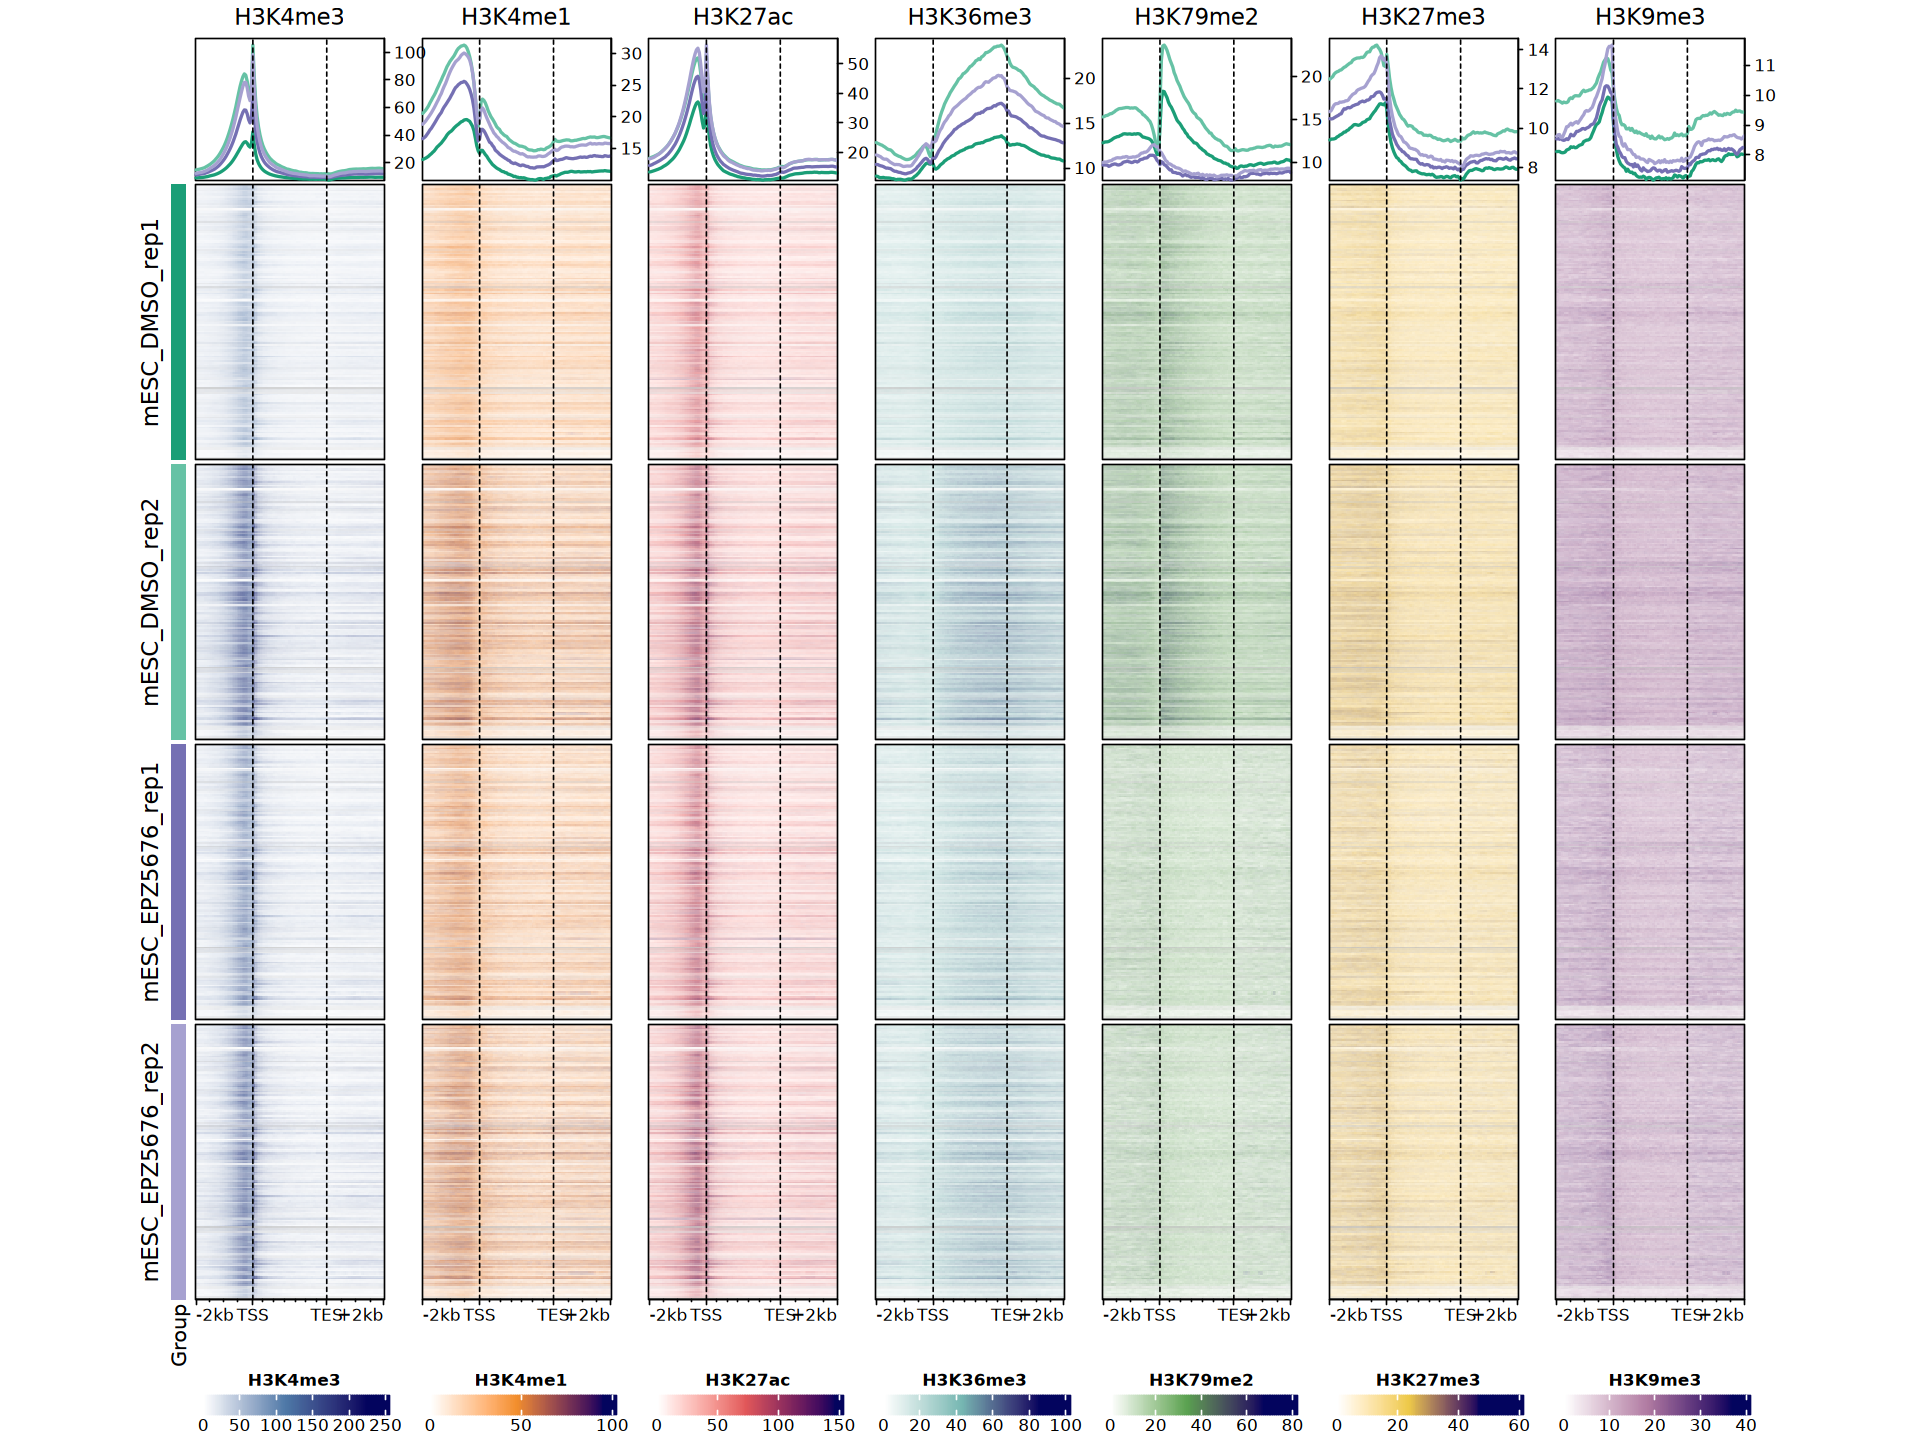

In [29]:
options(repr.plot.width = 16, repr.plot.height = 12)

draw(
    ht_list, split = partition, heatmap_legend_side = "bottom", 
    ht_gap = unit(c(2, rep(8, length(gene_mat_merged_list))), "mm"), 
    legend_gap = unit(8, "mm"))

# 5. Peak Annotation

In [30]:
suppressPackageStartupMessages(library(ChIPseeker))

In [31]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Gen

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


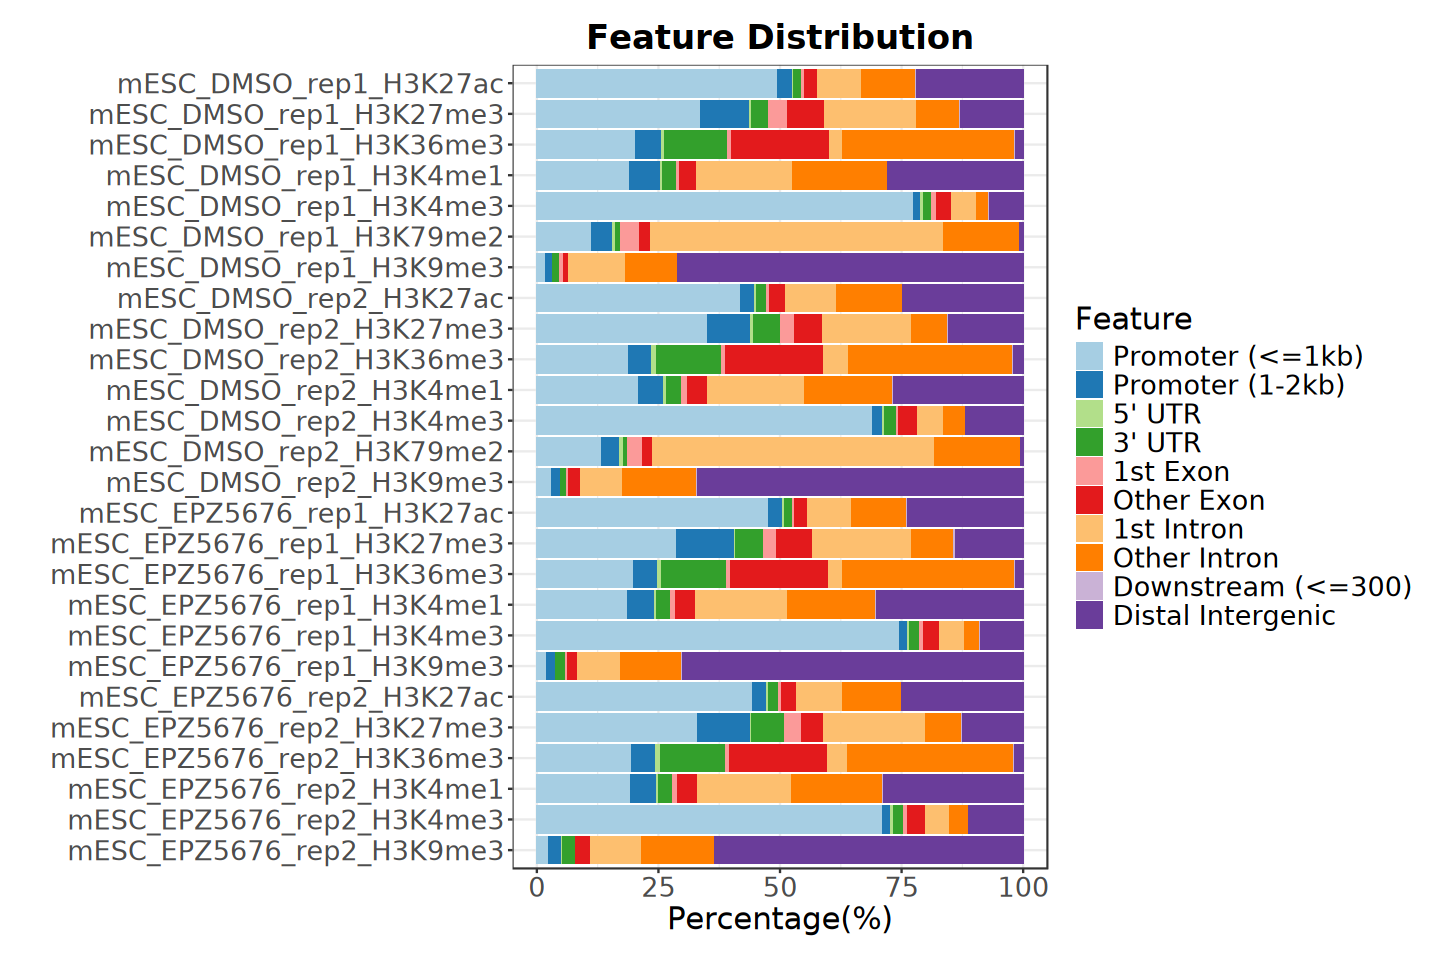

In [32]:
options(repr.plot.width = 12, repr.plot.height = 8)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

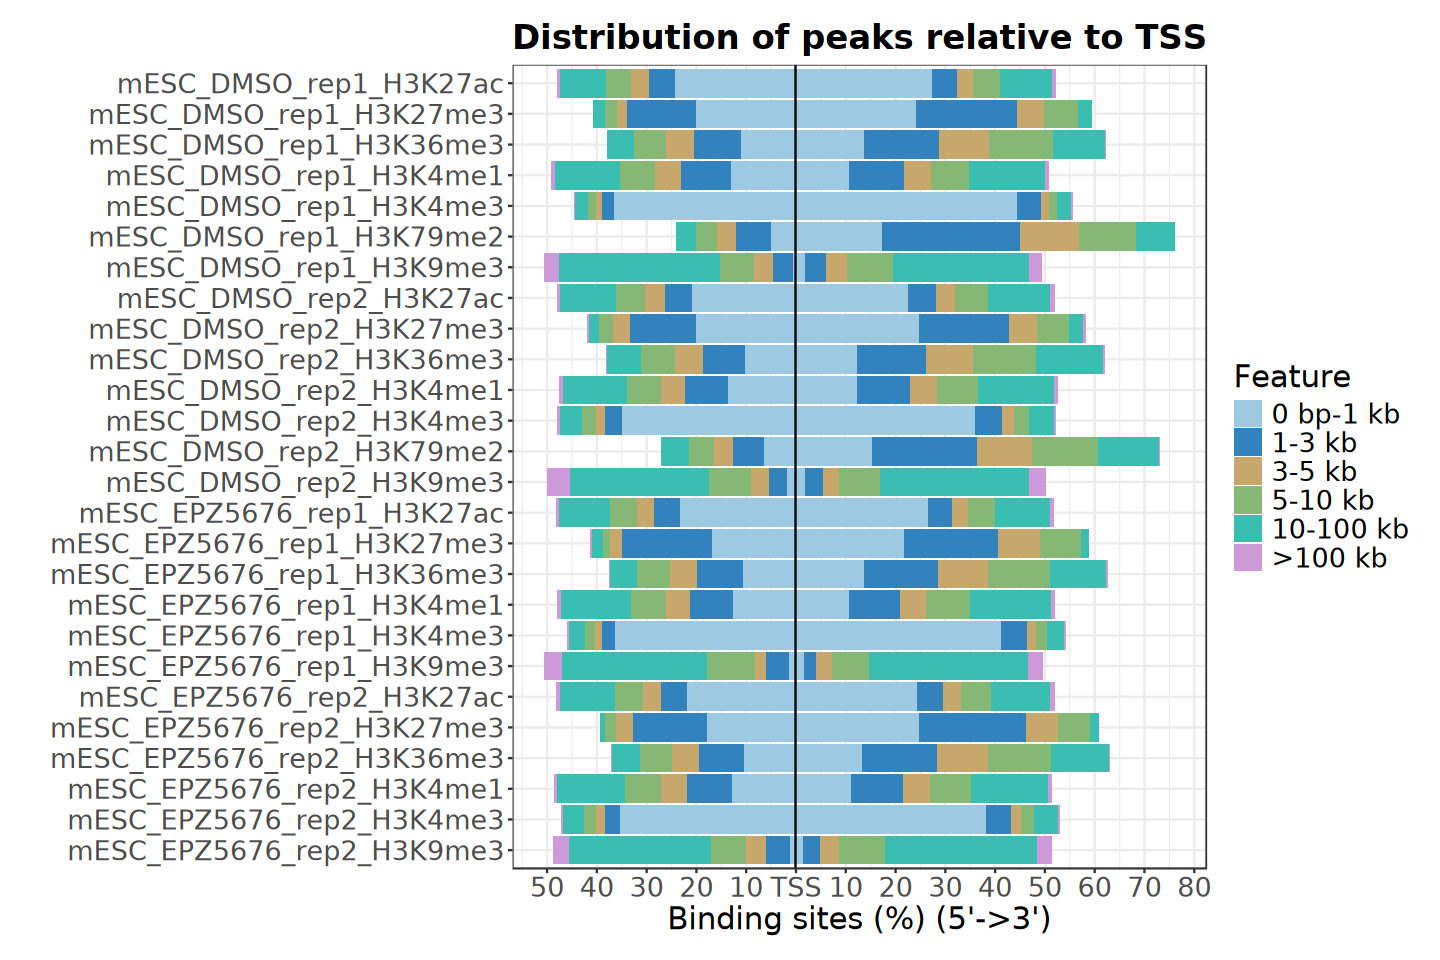

In [33]:
options(repr.plot.width = 12, repr.plot.height = 8)

plotDistToTSS(
    peaks_anno_list, title = "Distribution of peaks relative to TSS") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# * Reference